# 02 · Data quality

Checks both datasets for problems before the split. Every check ends with a decision:
**remove** (clear error), **flag** (unusual but real, keep), or **ok**.

Only clear errors are removed. Unusual images stay in, because the Kaggle test set contains
unusual images too and the model should learn them.

1. Completeness and format
2. Exact duplicates
3. Flat bands
4. Dead pixels
5. Very bright pixels
6. Possible label errors (spectral outliers)
7. Hazy images
8. Decisions and saved flags

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import (CLASSES, EUROSAT_MS_DIR, PROJECT_ROOT, TEST_BANDS, TEST_DIR,
                      band_index, load_test, load_train)
from src.plot_style import TRAIN_COLOR, TEST_COLOR, apply_style

apply_style()

X_train, meta = load_train(mmap=False)
X_test, test_ids = load_test(mmap=False)

# Per-image, per-band summaries used by several checks: shape (N, 12)
flat_train = X_train.reshape(len(X_train), 12, -1)
flat_test = X_test.reshape(len(X_test), 12, -1)
std_train, std_test = flat_train.std(axis=2), flat_test.std(axis=2)
mean_train = flat_train.mean(axis=2)

flags = meta[["path", "label"]].copy()

In [2]:
def to_rgb(img, vmax=2750):
    """(12, 64, 64) image -> (64, 64, 3) RGB with fixed scaling."""
    rgb = img[[band_index("B04"), band_index("B03"), band_index("B02")]].astype(np.float32)
    return np.clip(rgb / vmax, 0, 1).transpose(1, 2, 0)

def show_gallery(indices, titles, ncols=8, size=1.6, vmax=2750):
    """Show training images as RGB thumbnails."""
    indices = list(indices)
    nrows = max(1, int(np.ceil(len(indices) / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i, t in zip(axes.flat, indices, titles):
        ax.imshow(to_rgb(X_train[i], vmax))
        ax.set_title(t, fontsize=7)
    plt.tight_layout()
    plt.show()

## 1 · Completeness and format

Every file listed in `train.csv` and `test.csv` exists, has the expected shape and type, and the
class counts match EuroSAT.

In [3]:
checks = {
    "train.csv rows": len(meta),
    "train files on disk": sum(1 for _ in EUROSAT_MS_DIR.glob("*/*.tif")),
    "train files missing": int(sum(not (EUROSAT_MS_DIR / p).exists() for p in meta["path"])),
    "train labels outside the 10 classes": int((~meta["label"].isin(CLASSES)).sum()),
    "test.csv rows": len(test_ids),
    "test files on disk": sum(1 for _ in TEST_DIR.glob("*.npy")),
    "test ids without a file": int(sum(not (TEST_DIR / f"test_{i}.npy").exists() for i in test_ids["test_id"])),
    "train array shape": str(X_train.shape),
    "test array shape": str(X_test.shape),
}
pd.Series(checks, name="value").to_frame()

,value
train.csv rows,27000
train files on disk,27000
train files missing,0
train labels outside the 10 classes,0
test.csv rows,4232
test files on disk,4232
test ids without a file,0
train array shape,"(27000, 12, 64, 64)"
test array shape,"(4232, 12, 64, 64)"


**Decision: ok.** All files are present and readable, with the expected format.

## 2 · Exact duplicates

Identical images (byte for byte) within each dataset.

In [4]:
def n_duplicates(x):
    hashes = pd.Series([hash(img.tobytes()) for img in x])
    return int(hashes.duplicated().sum())

pd.Series({"train": n_duplicates(X_train), "test": n_duplicates(X_test)}, name="duplicate images").to_frame()

,duplicate images
train,0
test,0


**Decision: ok.** No duplicates.

## 3 · Flat bands

A band where every pixel has the same value can mean a missing band or a broken file.

SeaLake/SeaLake_296.tif        flat band(s): ['B09'], value 64
SeaLake/SeaLake_159.tif        flat band(s): ['B09'], value 64
SeaLake/SeaLake_2159.tif       flat band(s): ['B09'], value 64
Test images with a flat band: 0


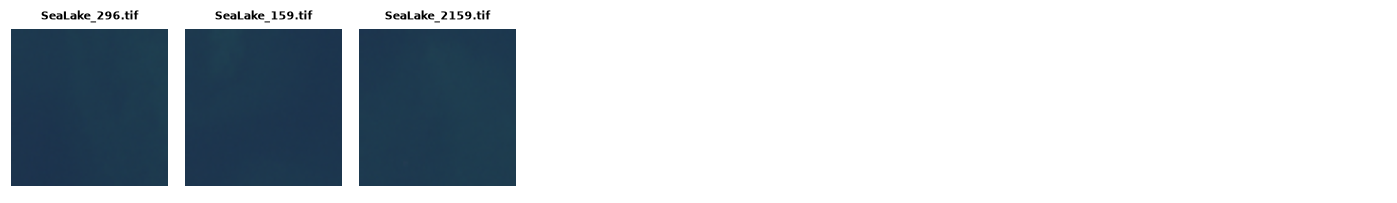

In [5]:
flat_band = std_train == 0
for i in np.flatnonzero(flat_band.any(axis=1)):
    bands = [TEST_BANDS[b] for b in np.flatnonzero(flat_band[i])]
    print(f"{meta.path[i]:30} flat band(s): {bands}, value {int(X_train[i, flat_band[i]].ravel()[0])}")
print(f"Test images with a flat band: {(std_test == 0).any(axis=1).sum()}")

flags["flat_band"] = flat_band.any(axis=1)
show_gallery(np.flatnonzero(flags["flat_band"]), meta.path[flags["flat_band"]].str.split("/").str[1])

**Decision: ok (flag only).** All three are calm open water, and only **B09** is flat. B09 has a coarse
60 m resolution, so a 64 × 64 patch of uniform water can easily have one value. B09 is also the band that differs most
between training and test images (see `01_eda`), so it is a candidate for dropping in a later experiment.

## 4 · Dead pixels

Pixels with value 0 (no data).

In [6]:
zeros_train = (flat_train == 0).sum(axis=(1, 2))
zeros_test = (flat_test == 0).sum(axis=(1, 2))
print(f"Train: {(zeros_train > 0).sum()} images, {zeros_train.sum()} zero pixels in total, max {zeros_train.max()} in one image")
print(f"Test:  {(zeros_test > 0).sum()} images, {zeros_test.sum()} zero pixels in total")
print("Classes:", meta.loc[zeros_train > 0, "label"].value_counts().to_dict())

flags["dead_pixels"] = zeros_train > 0

Train: 7 images, 18 zero pixels in total, max 10 in one image
Test:  1 images, 4 zero pixels in total
Classes: {'Residential': 7}


**Decision: ok (flag only).** At most a handful of single pixels per image out of 49,152.
Normalisation and clipping make them harmless.

## 5 · Very bright pixels

Values of 10,000 or more (reflectance above 100%). These can come from clouds or snow, but also
from shiny roofs and glare.

Train: 391 images, median 8 bright pixels per affected image
Test:  60 images, median 6 bright pixels per affected image
Train images where more than 5% of pixels are bright: 1


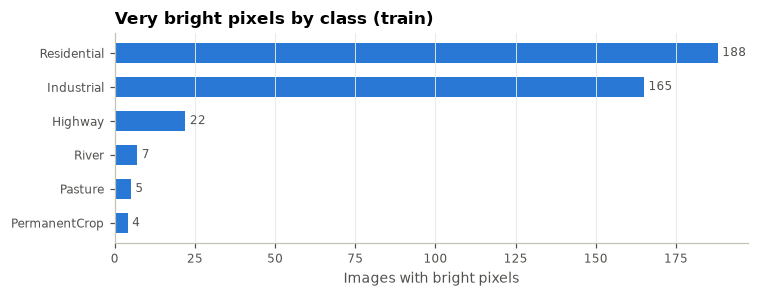

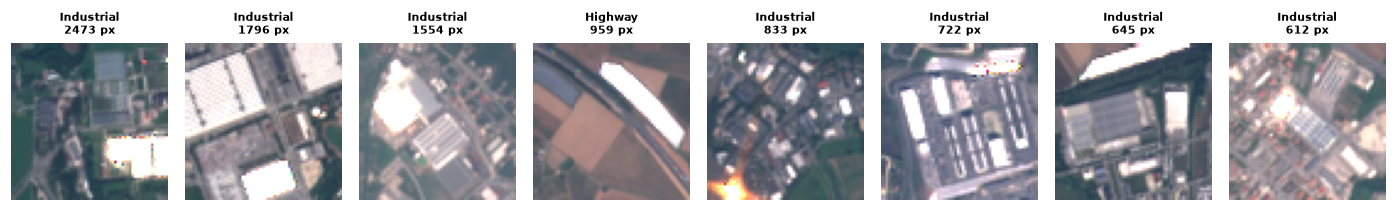

In [7]:
bright_train = (flat_train >= 10_000).sum(axis=(1, 2))
bright_test = (flat_test >= 10_000).sum(axis=(1, 2))
print(f"Train: {(bright_train > 0).sum()} images, median {np.median(bright_train[bright_train > 0]):.0f} bright pixels per affected image")
print(f"Test:  {(bright_test > 0).sum()} images, median {np.median(bright_test[bright_test > 0]):.0f} bright pixels per affected image")
print(f"Train images where more than 5% of pixels are bright: {(bright_train > 0.05 * 12 * 64 * 64).sum()}")

by_class = meta.loc[bright_train > 0, "label"].value_counts()
fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(by_class.index[::-1], by_class.values[::-1], color=TRAIN_COLOR, height=0.6)
ax.bar_label(bars, padding=3, fontsize=8, color="#52514e")
ax.set_xlabel("Images with bright pixels")
ax.set_title("Very bright pixels by class (train)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

flags["bright_pixels"] = bright_train > 0
top = np.argsort(bright_train)[::-1][:8]
show_gallery(top, [f"{meta.label[i]}\n{bright_train[i]} px" for i in top])

**Decision: ok (flag only).** Almost all are Residential and Industrial images with a few very bright
pixels: roofs, greenhouses and glare. They are real, and the test set has them too (60 images).
They are kept as they are: values stay far below the data type's limit, and normalisation per band keeps them from dominating.

## 6 · Possible label errors (spectral outliers)

For each class, how far is each image's mean spectrum from the typical spectrum of its class?
Uses a robust z-score (median and median absolute deviation) on the log of each band's mean,
averaged over bands. The highest-scoring images are the most unusual for their label:
either a wrong label or simply a rare example.

In [8]:
log_spec = np.log1p(mean_train)
outlier_score = np.zeros(len(meta))
for cls in CLASSES:
    idx = np.flatnonzero(meta["label"] == cls)
    med = np.median(log_spec[idx], axis=0)
    mad = np.median(np.abs(log_spec[idx] - med), axis=0) * 1.4826 + 1e-6
    outlier_score[idx] = np.abs((log_spec[idx] - med) / mad).mean(axis=1)

# Flag the 1% most unusual images of each class
flags["outlier_score"] = outlier_score.round(2)
flags["spectral_outlier"] = flags.groupby("label")["outlier_score"].rank(pct=True) > 0.99
print(f"Flagged: {flags['spectral_outlier'].sum()} images")

Flagged: 273 images


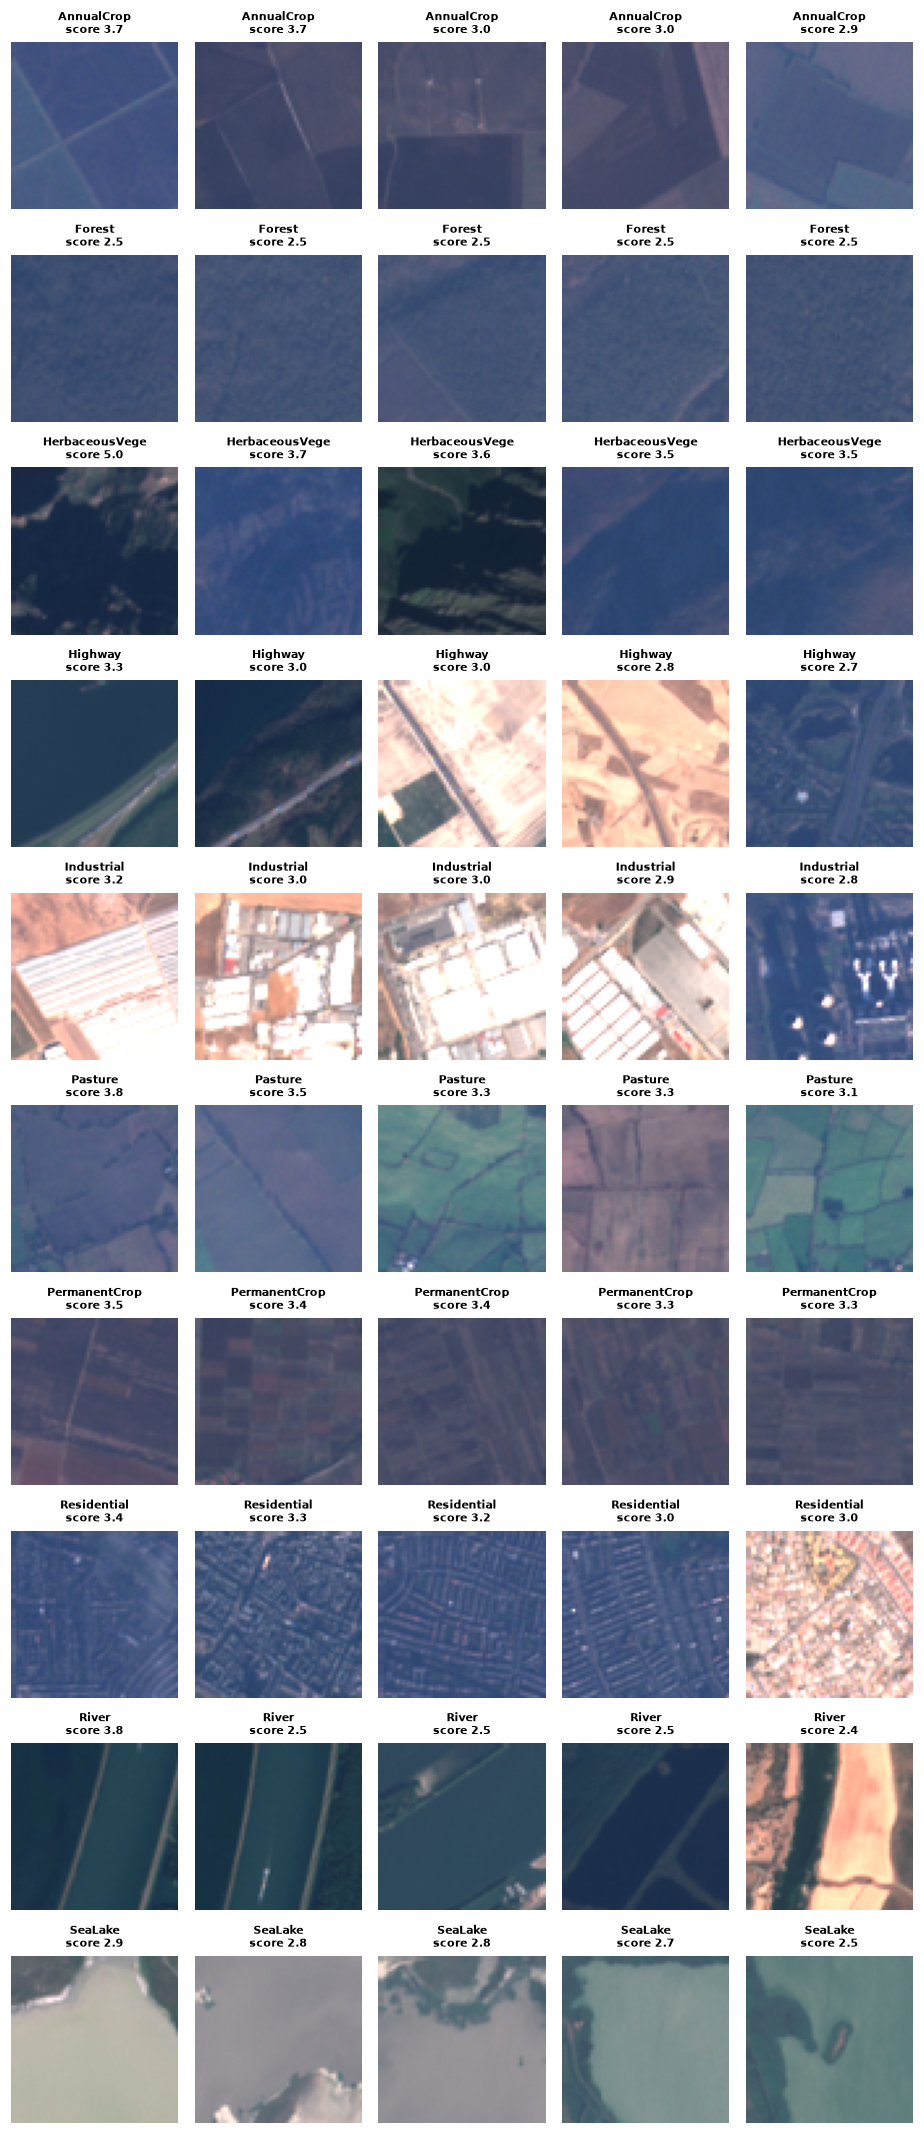

In [9]:
# The 5 most unusual images per class, row by row
idx = []
titles = []
for cls in CLASSES:
    top = flags[flags["label"] == cls].nlargest(5, "outlier_score").index
    idx += list(top)
    titles += [f"{cls[:14]}\nscore {outlier_score[i]:.1f}" for i in top]
show_gallery(idx, titles, ncols=5, size=1.7)

**Decision: flag, don't remove.** Most of the most unusual images are **hazy**: they have the bluish,
low-contrast look of atmospheric haze, which pushes their spectrum away from the class average
(compare with section 7). The rest are rare but plausible scenes, such as very bright industrial
roofs, sandy river banks, or turquoise and bright lakes. None of the top images is clearly
mislabelled. Removing them would make the model worse at exactly the unusual cases. If the team
finds images that are clearly mislabelled, add their paths to `MANUAL_REMOVE` in section 8.

## 7 · Hazy images

EuroSAT was deliberately not filtered for haze (paper, Fig. 7). The aerosol band B01 is a simple haze
indicator: haze scatters short wavelengths, so hazy images are bright in B01 relative to their class.

Hazy images (B01 more than 3 std above the class median): 357
{'Residential': 68, 'River': 68, 'Highway': 50, 'Forest': 46, 'SeaLake': 38, 'Industrial': 32, 'PermanentCrop': 18, 'AnnualCrop': 17, 'Pasture': 14, 'HerbaceousVegetation': 6}


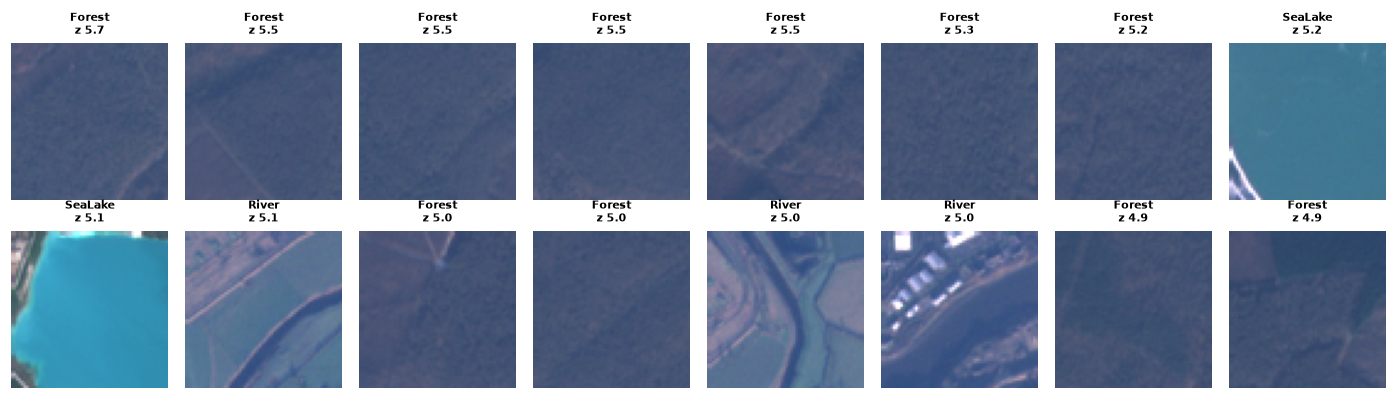

In [10]:
b01 = mean_train[:, band_index("B01")]
haze_z = np.zeros(len(meta))
for cls in CLASSES:
    idx = np.flatnonzero(meta["label"] == cls)
    haze_z[idx] = (b01[idx] - np.median(b01[idx])) / (np.std(b01[idx]) + 1e-6)
flags["haze_score"] = haze_z.round(2)
flags["hazy"] = haze_z > 3
print(f"Hazy images (B01 more than 3 std above the class median): {flags['hazy'].sum()}")
print(flags.loc[flags["hazy"], "label"].value_counts().to_dict())

top = np.argsort(haze_z)[::-1][:16]
show_gallery(top, [f"{meta.label[i][:14]}\nz {haze_z[i]:.1f}" for i in top])

**Decision: ok (flag only).** Hazy images are part of the training data on purpose. They are also a useful
reminder of what atmospheric correction removes: the test images don't have this haze.

## 8 · Decisions and saved flags

| Check | Train images affected | Decision |
|---|---|---|
| Completeness and format | 0 | ok |
| Exact duplicates | 0 | ok |
| Flat bands | 3 (water, B09 only) | flag |
| Dead pixels | 7 (single pixels) | flag |
| Very bright pixels | 391 (roofs, glare) | flag |
| Spectral outliers | top 1% per class | flag, review manually |
| Hazy images | see section 7 | flag |

**No image is removed automatically.** The flags are saved so later notebooks can, for example,
look at how the model does on hazy or unusual images.

In [11]:
# Paths of images the team decides to remove after manual review, e.g. "Forest/Forest_123.tif"
MANUAL_REMOVE: list[str] = []

flags["remove"] = flags["path"].isin(MANUAL_REMOVE)

out = PROJECT_ROOT / "artifacts" / "quality_flags.csv"
out.parent.mkdir(exist_ok=True)
flags.to_csv(out, index=False)

summary = flags[["flat_band", "dead_pixels", "bright_pixels", "spectral_outlier", "hazy", "remove"]].sum()
print(f"Saved {out.relative_to(PROJECT_ROOT)}")
summary.rename("images").to_frame()

Saved artifacts/quality_flags.csv


,images
flat_band,3
dead_pixels,7
bright_pixels,391
spectral_outlier,273
hazy,357
remove,0
